# E-Commerce Sales & Customer Analytics


## Project Objective

The objective of this project is to analyze e-commerce transaction data
using Python to identify sales trends, customer purchasing behavior,
product performance, and geographical sales patterns.

The analysis will help understand:
- Overall sales and revenue performance
- Monthly and yearly sales trends
- Best and worst performing products
- Customer purchasing behavior
- Sales performance across different countries
- Key factors affecting business performance

The final insights will be presented through an interactive Power BI dashboard.

## 1. Importing Required Libraries

The following Python libraries will be used for data manipulation,
numerical analysis, exploratory data analysis, and visualization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
## 2. Loading the Dataset

In [3]:
df = pd.read_csv("data.csv", encoding="ISO-8859-1")

In [4]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [5]:
df.shape

(541909, 8)

In [6]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [8]:
missing_values = df.isnull().sum()
missing_percentage = ( missing_values / len(df)*100)
missing_df = pd.DataFrame({
    'missing Values': missing_values,
    'Percentage': missing_percentage
})
missing_df

,missing Values,Percentage
InvoiceNo,0,0.000000
StockCode,0,0.000000
Description,1454,0.268311
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
CustomerID,135080,24.926694
Country,0,0.000000


In [9]:
## 5. Analyzing Missing Product Descriptions

In [10]:
df[df['Description'].isnull()].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,12/1/2010 11:52,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,12/1/2010 14:32,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,12/1/2010 14:33,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,12/1/2010 14:33,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,12/1/2010 14:34,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,12/1/2010 14:34,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,12/1/2010 14:34,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,12/1/2010 14:35,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,12/1/2010 14:35,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,12/1/2010 16:50,0.0,NaN,United Kingdom


In [11]:
## 6. Investigating Missing Product Information


In [12]:
df[df['Description'].isnull()]['UnitPrice'].value_counts()

UnitPrice
0.0    1454
Name: count, dtype: int64

In [13]:
## 7. Handling Missing Product Descriptions

In [14]:
df = df.dropna(subset=['Description'])

In [15]:
df['Description'].isnull().sum()

np.int64(0)

In [16]:
df.shape


(540455, 8)

In [17]:
## 8. Analyzing Missing Customer IDs

In [18]:
df['CustomerID'].isnull().sum()

np.int64(133626)

In [19]:
df['CustomerID'].notnull().sum()

np.int64(406829)

In [20]:
## 9. CustomerID Availability Analysis

In [21]:
df.groupby(df['CustomerID'].isnull())['UnitPrice'].agg(['count','mean','min','max'])

,count,mean,min,max
CustomerID,,,,
False,406829,3.460471,0.00,38970.00
True,133626,8.164459,-11062.06,17836.46


In [22]:
## 10. Duplicate Record Analysis

In [23]:
df.duplicated().sum()

np.int64(5268)

In [24]:
## 11. Handling Duplicate Records

In [25]:
df = df.drop_duplicates()

In [26]:
df.shape

(535187, 8)

In [27]:
df.duplicated().sum()

np.int64(0)

In [28]:
## 12. Quantity Analysis

In [29]:
df['Quantity'].describe()

count    535187.000000
mean          9.671593
std         219.059056
min      -80995.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       80995.000000
Name: Quantity, dtype: float64

In [30]:
df['Quantity'].value_counts().sort_index().head(20)

Quantity
-80995    1
-74215    1
-9600     2
-9360     1
-9058     1
-5368     1
-4830     1
-3114     1
-3100     1
-3000     1
-2880     1
-2618     1
-2600     1
-2472     1
-2376     1
-2003     1
-2000     1
-1930     1
-1897     1
-1681     1
Name: count, dtype: int64

In [31]:
print("Negative quantities:", (df['Quantity']<0).sum())
print("zero quantities:", (df['Quantity'] ==0).sum())
print("Positive quantities:", (df['Quantity'] > 0).sum())

Negative quantities: 9725
zero quantities: 0
Positive quantities: 525462


In [32]:
## 13. Investigating Cancelled Transactions

In [33]:
negative_qty = df[df['Quantity'] <0]
negative_qty['InvoiceNo'].astype(str).str.startswith('C').value_counts()

InvoiceNo
True     9251
False     474
Name: count, dtype: int64

In [34]:

negative_non_cancelled = negative_qty[
    ~negative_qty['InvoiceNo'].astype(str).str.startswith('C')
    ]
negative_non_cancelled.head(20)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
7313,537032,21275,?,-30,12/3/2010 16:50,0.0,NaN,United Kingdom
13217,537425,84968F,check,-20,12/6/2010 15:35,0.0,NaN,United Kingdom
13218,537426,84968E,check,-35,12/6/2010 15:36,0.0,NaN,United Kingdom
13264,537432,35833G,damages,-43,12/6/2010 16:10,0.0,NaN,United Kingdom
21338,538072,22423,faulty,-13,12/9/2010 14:10,0.0,NaN,United Kingdom
21518,538090,20956,?,-723,12/9/2010 14:48,0.0,NaN,United Kingdom
22296,538161,46000S,Dotcom sales,-100,12/9/2010 17:25,0.0,NaN,United Kingdom
22297,538162,46000M,Dotcom sales,-100,12/9/2010 17:25,0.0,NaN,United Kingdom
42564,540010,22501,reverse 21/5/10 adjustment,-100,1/4/2011 11:13,0.0,NaN,United Kingdom
42566,540012,22502,reverse 21/5/10 adjustment,-100,1/4/2011 11:14,0.0,NaN,United Kingdom


In [35]:
## 14. Handling Invalid Zero-Price Transactions

In [36]:
df[(df['Quantity'] < 0) & (df['UnitPrice'] == 0)].shape

(474, 8)

In [37]:
df = df[~((df['Quantity'] < 0) & (df['UnitPrice'] == 0))]

In [38]:
df.shape

(534713, 8)

In [39]:
df[df['Quantity']< 0].shape

(9251, 8)

In [40]:
## 15. Removing Cancelled Transactions

In [41]:
df = df[df['Quantity'] > 0]

In [42]:
df.shape

(525462, 8)

In [43]:
## 16. Checking Unit Price

In [44]:
print("Zero UnitPrice:", (df['UnitPrice'] == 0).sum())
print("Negative UnitPrice:", (df['UnitPrice'] < 0).sum())
print("Positive UnitPrice:", (df['UnitPrice'] > 0).sum())
      

Zero UnitPrice: 582
Negative UnitPrice: 2
Positive UnitPrice: 524878


In [45]:
df[df['UnitPrice'] <= 0][
    ['InvoiceNo', 'StockCode', 'Description', 'Quantity',
     'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
    ].head(20)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
6391,536941,22734,amazon,20,12/3/2010 12:08,0.0,NaN,United Kingdom
6392,536942,22139,amazon,15,12/3/2010 12:08,0.0,NaN,United Kingdom
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,12/5/2010 14:02,0.0,12647.0,Germany
14335,537534,85064,CREAM SWEETHEART LETTER RACK,1,12/7/2010 11:48,0.0,NaN,United Kingdom
14336,537534,84832,ZINC WILLIE WINKIE CANDLE STICK,1,12/7/2010 11:48,0.0,NaN,United Kingdom
14337,537534,84692,BOX OF 24 COCKTAIL PARASOLS,2,12/7/2010 11:48,0.0,NaN,United Kingdom
14338,537534,48184,DOORMAT ENGLISH ROSE,3,12/7/2010 11:48,0.0,NaN,United Kingdom
14339,537534,48111,DOORMAT 3 SMILEY CATS,1,12/7/2010 11:48,0.0,NaN,United Kingdom
14340,537534,22697,GREEN REGENCY TEACUP AND SAUCER,1,12/7/2010 11:48,0.0,NaN,United Kingdom
14341,537534,22682,FRENCH BLUE METAL DOOR SIGN 7,1,12/7/2010 11:48,0.0,NaN,United Kingdom


In [46]:
df[df['UnitPrice'] <0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,8/12/2011 14:51,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,8/12/2011 14:52,-11062.06,NaN,United Kingdom


In [47]:
## 17. Removing Invalid Price Transactions

In [48]:
df = df[df['UnitPrice'] >0]

In [49]:
df.shape

(524878, 8)

In [50]:
## 18. Converting InvoiceDate to Datetime

In [51]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

In [52]:
df['InvoiceDate'].dtype

dtype('<M8[ns]')

In [53]:
## 19. Creating Revenue


In [54]:
df['Revenue'] = df['Quantity'] * df['UnitPrice']

In [55]:
df[['Quantity', 'UnitPrice', 'Revenue']].head()

,Quantity,UnitPrice,Revenue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [56]:
print("Zero Revenue:", (df['Revenue'] == 0).sum())
print("Negative Revenue:", (df['Revenue'] < 0).sum())
print("Positive Revenue:", (df['Revenue'] > 0).sum())

Zero Revenue: 0
Negative Revenue: 0
Positive Revenue: 524878


In [57]:

## 20. Creating Time-Based Features


In [58]:
df['Year'] = df['InvoiceDate'].dt.year 
df['Month'] = df['InvoiceDate'].dt.month
df['MonthName'] = df['InvoiceDate'].dt.month_name()
df['Day'] = df['InvoiceDate'].dt.day
df['Hour'] = df['InvoiceDate'].dt.hour

In [59]:
df[['InvoiceDate', 'Year', 'Month', 'MonthName', 'Day', 'Hour']].head()

,InvoiceDate,Year,Month,MonthName,Day,Hour
0,2010-12-01 08:26:00,2010,12,December,1,8
1,2010-12-01 08:26:00,2010,12,December,1,8
2,2010-12-01 08:26:00,2010,12,December,1,8
3,2010-12-01 08:26:00,2010,12,December,1,8
4,2010-12-01 08:26:00,2010,12,December,1,8


In [60]:
## 21. Monthly Revenue Analysis

In [61]:
monthly_revenue = (
    df.groupby(['Year', 'Month', 'MonthName', ])['Revenue']
    .sum()
    .reset_index()
)
monthly_revenue

,Year,Month,MonthName,Revenue
0,2010,12,December,821452.730
1,2011,1,January,689811.610
2,2011,2,February,522545.560
3,2011,3,March,716215.260
4,2011,4,April,536968.491
5,2011,5,May,769296.610
6,2011,6,June,760547.010
7,2011,7,July,718076.121
8,2011,8,August,757841.380
9,2011,9,September,1056435.192


In [62]:

## 22. Creating a Month-Year Feature

In [63]:
df['MonthYear'] = df['InvoiceDate'].dt.to_period('M')

In [64]:
df[['InvoiceDate', 'MonthYear']].head()

,InvoiceDate,MonthYear
0,2010-12-01 08:26:00,2010-12
1,2010-12-01 08:26:00,2010-12
2,2010-12-01 08:26:00,2010-12
3,2010-12-01 08:26:00,2010-12
4,2010-12-01 08:26:00,2010-12


In [65]:
monthly_revenue = (
    df.groupby('MonthYear')['Revenue']
    .sum()
    .reset_index()
)
monthly_revenue

,MonthYear,Revenue
0,2010-12,821452.730
1,2011-01,689811.610
2,2011-02,522545.560
3,2011-03,716215.260
4,2011-04,536968.491
5,2011-05,769296.610
6,2011-06,760547.010
7,2011-07,718076.121
8,2011-08,757841.380
9,2011-09,1056435.192


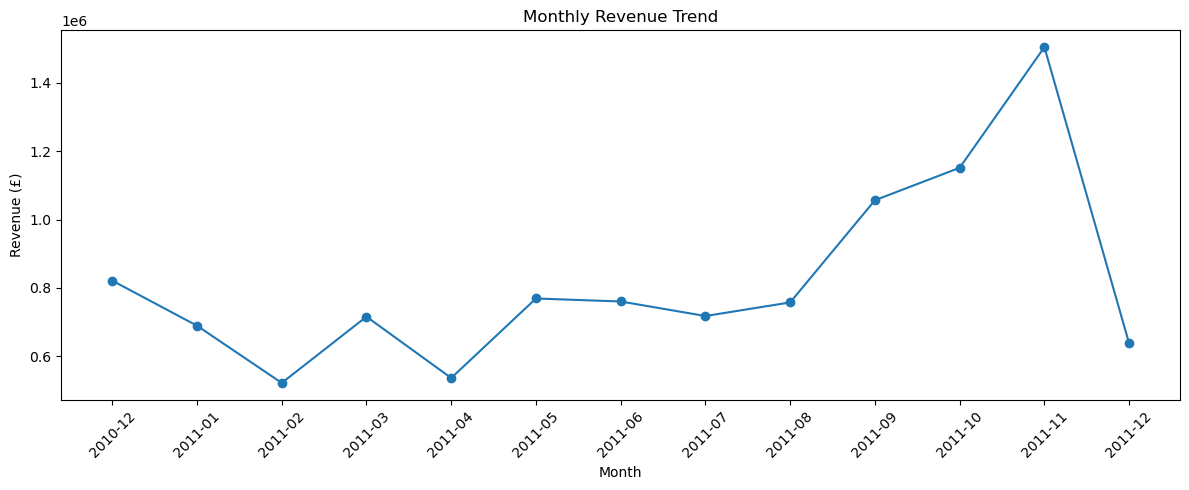

In [66]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue['MonthYear'].astype(str),
    monthly_revenue['Revenue'],
    marker='o'
)
plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Monthly Revenue Insights

The monthly revenue analysis shows significant variation in sales performance
throughout the period.

- November 2011 recorded the highest revenue at approximately £1.50 million.
- February 2011 recorded the lowest revenue among the complete months at
  approximately £523 thousand.
- Revenue increased significantly from September to November 2011.
- December 2011 shows lower revenue, but this month is incomplete in the
  dataset, so it should not be directly compared with complete months.

Overall, the business experienced strong revenue growth during the second
half of 2011, particularly between September and November.

In [67]:
## 23. Overall Sales KPIs

In [68]:
total_revenue = df['Revenue'].sum()
total_revenue

np.float64(10642110.804000001)

In [69]:
print(f"Total Revenue: £{total_revenue:,.2f}")

Total Revenue: £10,642,110.80


In [70]:
## 24. Total Orders

In [71]:
total_orders = df['InvoiceNo'].nunique()
total_orders

19960

In [72]:
## 25. Total Quantity Sold

In [73]:
total_quantity = df['Quantity'].sum()
total_quantity

np.int64(5572420)

In [74]:
## 26. Total Customers

In [75]:
total_customer = df['CustomerID'].nunique()
total_customer

4338

In [76]:
## Calculate Average Order Value (AOV)

In [77]:
aov = total_revenue / total_orders
aov

np.float64(533.171883967936)

In [78]:
## 27. Product Revenue Analysis

In [79]:
top_products = (
    df.groupby('Description')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)
top_products

,Description,Revenue
0,DOTCOM POSTAGE,206248.77
1,REGENCY CAKESTAND 3 TIER,174156.54
2,"PAPER CRAFT , LITTLE BIRDIE",168469.60
3,WHITE HANGING HEART T-LIGHT HOLDER,106236.72
4,PARTY BUNTING,99445.23
5,JUMBO BAG RED RETROSPOT,94159.81
6,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
7,POSTAGE,78101.88
8,Manual,77752.82
9,RABBIT NIGHT LIGHT,66870.03


In [80]:
df['Description'].value_counts().head(20)

Description
WHITE HANGING HEART T-LIGHT HOLDER    2311
JUMBO BAG RED RETROSPOT               2109
REGENCY CAKESTAND 3 TIER              2007
PARTY BUNTING                         1699
LUNCH BAG RED RETROSPOT               1581
ASSORTED COLOUR BIRD ORNAMENT         1476
SET OF 3 CAKE TINS PANTRY DESIGN      1392
PACK OF 72 RETROSPOT CAKE CASES       1352
LUNCH BAG  BLACK SKULL.               1301
NATURAL SLATE HEART CHALKBOARD        1255
JUMBO BAG PINK POLKADOT               1232
HEART OF WICKER SMALL                 1219
JUMBO STORAGE BAG SUKI                1194
PAPER CHAIN KIT 50'S CHRISTMAS        1184
JUMBO SHOPPER VINTAGE RED PAISLEY     1180
JAM MAKING SET PRINTED                1164
LUNCH BAG SPACEBOY DESIGN             1164
LUNCH BAG CARS BLUE                   1162
SPOTTY BUNTING                        1154
JAM MAKING SET WITH JARS              1133
Name: count, dtype: int64

In [81]:
non_product_items = [
    'POSTAGE',
    'DOTCOM POSTAGE',
    'Manual'
]

product_df = df[~df['Description'].isin(non_product_items)].copy()

In [82]:
product_df.shape

(522729, 15)

In [83]:
top_products = (
    product_df.groupby('Description')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)
top_products

,Description,Revenue
0,REGENCY CAKESTAND 3 TIER,174156.54
1,"PAPER CRAFT , LITTLE BIRDIE",168469.60
2,WHITE HANGING HEART T-LIGHT HOLDER,106236.72
3,PARTY BUNTING,99445.23
4,JUMBO BAG RED RETROSPOT,94159.81
5,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
6,RABBIT NIGHT LIGHT,66870.03
7,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59
8,ASSORTED COLOUR BIRD ORNAMENT,58927.62
9,CHILLI LIGHTS,54096.36


In [84]:
## 28. Country Revenue Analysis

In [85]:
country_revenue=(
     df.groupby('Country')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)
country_revenue
    

,Country,Revenue
0,United Kingdom,9001744.094
1,Netherlands,285446.340
2,EIRE,283140.520
3,Germany,228678.400
4,France,209625.370
5,Australia,138453.810
6,Spain,61558.560
7,Switzerland,57067.600
8,Belgium,41196.340
9,Sweden,38367.830


In [86]:
## 29. Customer Revenue Analysis

In [87]:
customer_revenue = (
    df.dropna(subset=['CustomerID'])
    .groupby('CustomerID')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)
customer_revenue

,CustomerID,Revenue
0,14646.0,280206.02
1,18102.0,259657.30
2,17450.0,194390.79
3,16446.0,168472.50
4,14911.0,143711.17
5,12415.0,124914.53
6,14156.0,117210.08
7,17511.0,91062.38
8,16029.0,80850.84
9,12346.0,77183.60


### Customer Revenue Insights

Customer-level analysis shows that a small group of customers contributes
significantly to overall revenue.

- Customer 14646 generated the highest revenue at approximately £280 thousand.
- Customer 18102 generated approximately £260 thousand.
- Several other customers generated more than £100 thousand in revenue.
- This indicates the presence of high-value customers who contribute
  significantly to business revenue.

Identifying and retaining these high-value customers can help support
long-term revenue growth.

In [88]:
## 30. Customer Purchase Frequency

In [89]:
customer_orders = (
    df.dropna(subset=['CustomerID'])
    .groupby('CustomerID')['InvoiceNo']
    .nunique()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)
customer_orders

,CustomerID,InvoiceNo
0,12748.0,209
1,14911.0,201
2,17841.0,124
3,13089.0,97
4,14606.0,93
5,15311.0,91
6,12971.0,86
7,14646.0,73
8,16029.0,63
9,13408.0,62


### Customer Purchase Frequency Insights

Customer purchase frequency shows that some customers place orders much
more frequently than others.

- Customer 12748 placed the highest number of orders with 209 orders.
- Customer 14911 placed 201 orders.
- Customer 17841 placed 124 orders.
- The highest-revenue customer, Customer 14646, placed 73 orders.

This shows that high revenue and high purchase frequency are not necessarily
the same. Both metrics are useful for understanding customer behavior.

In [90]:
## 31. Product Quantity Analysis

In [91]:
top_quantity_product=(
    product_df.groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)
top_quantity_product

,Description,Quantity
0,"PAPER CRAFT , LITTLE BIRDIE",80995
1,MEDIUM CERAMIC TOP STORAGE JAR,78033
2,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951
3,JUMBO BAG RED RETROSPOT,48371
4,WHITE HANGING HEART T-LIGHT HOLDER,37872
5,POPCORN HOLDER,36749
6,PACK OF 72 RETROSPOT CAKE CASES,36396
7,ASSORTED COLOUR BIRD ORNAMENT,36362
8,RABBIT NIGHT LIGHT,30739
9,MINI PAINT SET VINTAGE,26633


### Product Quantity Insights

The product quantity analysis shows which products have the highest demand
based on units sold.

- PAPER CRAFT, LITTLE BIRDIE recorded the highest quantity sold with 80,995 units.
- MEDIUM CERAMIC TOP STORAGE JAR followed with 78,033 units.
- WORLD WAR 2 GLIDERS ASSTD DESIGNS recorded 54,951 units.
- Several products appear among the top performers in both quantity and revenue.

Overall, products with consistently high sales volume can be considered
important products for the business and may require sufficient inventory
availability.

In [92]:
## 32. Customer Average Order Value

In [93]:
customer_aov = (
    df.dropna(subset=['CustomerID'])
    .groupby('CustomerID')
    .agg(
        Total_Revenue = ('Revenue', 'sum'),
        Total_Orders = ('InvoiceNo', 'nunique')
    )
)
customer_aov['AOV'] = (
    customer_aov['Total_Revenue'] / customer_aov['Total_Orders']
)
cutomer_aov = (
    customer_aov.sort_values('AOV', ascending=False)
    .head(10)
    .reset_index()
)

customer_aov        
    

,Total_Revenue,Total_Orders,AOV
CustomerID,,,
12346.0,77183.60,1,77183.600000
12347.0,4310.00,7,615.714286
12348.0,1797.24,4,449.310000
12349.0,1757.55,1,1757.550000
12350.0,334.40,1,334.400000
...,...,...,...
18280.0,180.60,1,180.600000
18281.0,80.82,1,80.820000
18282.0,178.05,2,89.025000


### Customer AOV Insights

Customer AOV varies significantly across customers.

- Customer 12346 recorded the highest AOV because the customer made only one
  order with a very high transaction value.
- Customers with multiple orders generally show more representative AOV values.
- AOV should be considered together with total revenue and order frequency
  when evaluating customer value.
- This shows that a customer with a high AOV is not necessarily a frequent
  or high-revenue customer.

In [94]:
df.shape

(524878, 15)

## 33. Final Data Validation

Before importing the cleaned dataset into Power BI, the final dataset is
checked to ensure that the important fields contain valid values and that
the cleaning process has been completed successfully.

In [95]:
print("Dataset Shape:", df.shape)
print("Missing CustomerID:", df['CustomerID'].isnull().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("Zero Revenue:", (df['Revenue'] == 0).sum())
print("Negative Revenue:", (df['Revenue'] < 0).sum())
print("Zero UnitPrice:", (df['UnitPrice'] == 0).sum())
print("Negative UnitPrice:", (df['UnitPrice'] < 0).sum())
print("Negative Quantity:", (df['Quantity'] < 0).sum())


Dataset Shape: (524878, 15)
Missing CustomerID: 132186
Duplicate Rows: 0
Zero Revenue: 0
Negative Revenue: 0
Zero UnitPrice: 0
Negative UnitPrice: 0
Negative Quantity: 0


### Final Data Validation Summary

The final cleaned dataset contains 524,878 transaction records and 15 columns.

The data contains no duplicate rows, zero or negative revenue, zero or negative
unit prices, or negative quantities.

CustomerID remains missing for some transactions. These records were retained
because they are still useful for overall sales, product, country, and time
analysis. Customer-level analysis was performed only on transactions with a
valid CustomerID.

The dataset is now ready for Power BI dashboard development.

In [96]:
## 34. Export Cleaned Dataset

In [97]:
df.to_csv("ecommerce_cleaned.csv", index=False)

In [98]:
import os
print(os.path.exists("ecommerce_cleaned.csv"))

True


In [99]:
customer_summary = (
    df.dropna(subset=['CustomerID'])
      .groupby('CustomerID')
      .agg(
          Total_Revenue=('Revenue', 'sum'),
          Total_Orders=('InvoiceNo', 'nunique'),
          Total_Quantity=('Quantity', 'sum')
      )
      .reset_index()
)

customer_summary['Customer_AOV'] = (
    customer_summary['Total_Revenue'] /
    customer_summary['Total_Orders']
)

customer_summary.head()

,CustomerID,Total_Revenue,Total_Orders,Total_Quantity,Customer_AOV
0,12346.0,77183.60,1,74215,77183.600000
1,12347.0,4310.00,7,2458,615.714286
2,12348.0,1797.24,4,2341,449.310000
3,12349.0,1757.55,1,631,1757.550000
4,12350.0,334.40,1,197,334.400000


In [100]:
df[df['CustomerID'] == 12346][
    ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'UnitPrice', 'Revenue', 'InvoiceDate']
]


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Revenue,InvoiceDate
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.6,2011-01-18 10:01:00


In [101]:
df.nlargest(10, 'Quantity')[
    ['CustomerID', 'InvoiceNo', 'Description', 'Quantity', 'UnitPrice', 'Revenue']
]


,CustomerID,InvoiceNo,Description,Quantity,UnitPrice,Revenue
540421,16446.0,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60
61619,12346.0,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60
421632,12901.0,573008,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,1008.00
206121,13135.0,554868,SMALL POPCORN HOLDER,4300,0.72,3096.00
97432,18087.0,544612,EMPIRE DESIGN ROSETTE,3906,0.82,3202.92
270885,14609.0,560599,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06,191.16
52711,15749.0,540815,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40
160546,15749.0,550461,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40
433788,16308.0,573995,SMALL CHINESE STYLE SCISSOR,3000,0.32,960.00
4945,16754.0,536830,WORLD WAR 2 GLIDERS ASSTD DESIGNS,2880,0.18,518.40


In [102]:
customer_summary.to_csv("customer_summary.csv", index=False)

In [103]:
import os
os.path.exists("customer_summary.csv")


True

In [104]:
top_10_customer_revenue = customer_summary.nlargest(10, 'Total_Revenue')['Total_Revenue'].sum()
total_customer_revenue = customer_summary['Total_Revenue'].sum()
top_10_customer_percentage = (top_10_customer_revenue / total_customer_revenue)*100
print("top 10 customer revenue:", top_10_customer_revenue)
print("total customer revenue:", total_customer_revenue)
print("top 10 customer contribution:", top_10_customer_percentage)

top 10 customer revenue: 1537659.2100000002
total customer revenue: 8887208.894
top 10 customer contribution: 17.301936168487234


In [105]:
top_order_customer = customer_summary.nlargest(10, 'Total_Orders')[
    ['CustomerID', 'Total_Orders', 'Total_Revenue', 'Customer_AOV']
    ]
top_order_customer

,CustomerID,Total_Orders,Total_Revenue,Customer_AOV
326,12748.0,209,33053.19,158.149234
1879,14911.0,201,143711.17,714.980945
4010,17841.0,124,40519.84,326.772903
562,13089.0,97,58762.08,605.794639
1661,14606.0,93,12076.15,129.851075
2176,15311.0,91,60632.75,666.293956
481,12971.0,86,11189.91,130.115233
1689,14646.0,73,280206.02,3838.438630
2702,16029.0,63,80850.84,1283.346667
795,13408.0,62,28117.04,453.500645


In [106]:
overall_customer_aov= (
    customer_summary['Total_Revenue'].sum() /
    customer_summary['Total_Orders'].sum() 
)
customer_14646_aov = customer_summary.loc[
    customer_summary['CustomerID'] == 14646,
    'Customer_AOV'
    ].iloc[0]

aov_difference = customer_14646_aov / overall_customer_aov

print( "Overall Customer AOV:", overall_customer_aov)
print( "Customer 14646 AOV:", customer_14646_aov)
print( " AOV Multiple:", aov_difference)

Overall Customer AOV: 479.56016047917115
Customer 14646 AOV: 3838.4386301369864
 AOV Multiple: 8.004081544850726


## High-value customer behavior
Customer 14646 generated £280.21K from 73 orders, with an average order value of £3,838.44 — approximately 8× the overall customer AOV of £479.56. This indicates a high-value purchasing pattern and makes this customer particularly important for retention and relationship management.

In [107]:
top_10_product_revenue = (
    product_df.groupby('Description')['Revenue']
    .sum()
    .nlargest(10)
    .sum()
)

total_product_revenue = product_df['Revenue'].sum()

top_10_product_percentage = (
    top_10_product_revenue / total_product_revenue 
) * 100

print("Top 10 Product Revenue:", top_10_product_revenue)
print( " Total Product Revenue:", total_product_revenue)
print(" Top 10 Product Contribution:", top_10_product_percentage)

Top 10 Product Revenue: 968938.42
 Total Product Revenue: 10280007.334
 Top 10 Product Contribution: 9.425464287319544


## Top 10 products revenue contribution
The top 10 products generated approximately £968.9K, representing 9.43% of total product revenue. This indicates that revenue is relatively diversified across the product catalog rather than being heavily dependent on a small number of products.

Revenue appears more concentrated among high-value customers than among individual products, suggesting customer retention may be more critical than dependence on a small group of products.

In [108]:
top_quantity_product = (
    product_df.groupby('Description')
    .agg(
        Total_Quantity = ( 'Quantity', sum),
        Total_Revenue = ( 'Revenue', sum)
    )
    .sort_values('Total_Quantity', ascending=False)
    .head(10)
    .reset_index()
)

top_quantity_product
    

C:\Users\shank\AppData\Local\Temp\ipykernel_21788\3651811641.py:3: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  .agg(
C:\Users\shank\AppData\Local\Temp\ipykernel_21788\3651811641.py:3: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  .agg(


,Description,Total_Quantity,Total_Revenue
0,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
1,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92
2,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951,13814.01
3,JUMBO BAG RED RETROSPOT,48371,94159.81
4,WHITE HANGING HEART T-LIGHT HOLDER,37872,106236.72
5,POPCORN HOLDER,36749,34288.67
6,PACK OF 72 RETROSPOT CAKE CASES,36396,21246.45
7,ASSORTED COLOUR BIRD ORNAMENT,36362,58927.62
8,RABBIT NIGHT LIGHT,30739,66870.03
9,MINI PAINT SET VINTAGE,26633,16937.82


## product quantity vs revenue
Sales volume does not necessarily translate into revenue. WORLD WAR 2 GLIDERS ASSTD DESIGNS sold 54,951 units but generated only £13.81K, while PAPER CRAFT, LITTLE BIRDIE generated £168.47K from 80,995 units. This highlights the impact of product pricing on revenue performance.

In [109]:
uk_revenue =df.loc[
    df['Country'] == 'United Kingdom',
    'Revenue' 
    ].sum()
uk_percentage = ( uk_revenue / df['Revenue'].sum())*100

print( "UK Revenue:", uk_revenue)
print( "UK Revenue Contribution:", uk_percentage)

UK Revenue: 9001744.094
UK Revenue Contribution: 84.58607751590554


### Country Revenue Analysis

The United Kingdom generated £9.00 million in revenue, contributing approximately 84.6% of the total revenue.

This indicates that the business is highly dependent on the UK market, while other countries contribute a relatively smaller share of total revenue.

The high concentration of revenue in one country suggests that international markets could provide opportunities for future business growth and diversification.

In [110]:
uk_orders =df.loc[
    df['Country'] == 'United Kingdom',
    'InvoiceNo'
    ].nunique()

total_orders = df['InvoiceNo'].nunique()

uk_orders_percentage =(
    uk_orders / total_orders
)*100

print( "UK Orders:", uk_orders)
print( "UK Orders Contribution:", uk_orders_percentage)

UK Orders: 18019
UK Orders Contribution: 90.2755511022044


### UK Order Contribution Analysis

The United Kingdom accounted for 18,019 orders, representing approximately 90.3% of total orders.

The UK contributes a higher percentage of total orders (90.3%) than total revenue (84.6%). This indicates that orders from other countries have, on average, a relatively higher order value than orders from the UK.

Overall, the business is strongly dependent on the UK market in terms of both order volume and revenue.

In [111]:
country_aov = (
    df.groupby('Country')
    .agg(
        Total_Revenue=('Revenue', 'sum'),
        Total_Orders=('InvoiceNo', 'nunique')
    )
    .reset_index()
)
country_aov['AOV'] = (
    country_aov['Total_Revenue'] / country_aov['Total_Orders']
)

country_aov.sort_values('AOV', ascending=False).head(10)
                    

,Country,Total_Revenue,Total_Orders,AOV
30,Singapore,21279.29,7,3039.898571
24,Netherlands,285446.34,94,3036.663191
0,Australia,138453.81,57,2429.014211
20,Japan,37416.37,19,1969.282632
21,Lebanon,1693.88,1,1693.880000
16,Hong Kong,15483.00,11,1407.545455
4,Brazil,1143.60,1,1143.600000
32,Sweden,38367.83,36,1065.773056
33,Switzerland,57067.60,54,1056.807407
9,Denmark,18955.34,18,1053.074444


In [112]:
country_aov.sort_values('AOV', ascending=False).head(10).reset_index(drop=True)

,Country,Total_Revenue,Total_Orders,AOV
0,Singapore,21279.29,7,3039.898571
1,Netherlands,285446.34,94,3036.663191
2,Australia,138453.81,57,2429.014211
3,Japan,37416.37,19,1969.282632
4,Lebanon,1693.88,1,1693.880000
5,Hong Kong,15483.00,11,1407.545455
6,Brazil,1143.60,1,1143.600000
7,Sweden,38367.83,36,1065.773056
8,Switzerland,57067.60,54,1056.807407
9,Denmark,18955.34,18,1053.074444


### Country-wise Average Order Value Analysis

The Average Order Value varies significantly across countries.

Singapore recorded the highest AOV at approximately £3,039.90 per order, followed closely by the Netherlands at £3,036.66. However, Singapore had only 7 orders, so its high AOV should be interpreted cautiously.

The Netherlands is more significant because it generated £285,446.34 from 94 orders while maintaining an AOV of approximately £3,036.66.

This indicates that some international markets, particularly the Netherlands, generate higher-value orders and may represent opportunities for further business growth.

In [113]:
international_revenue = (
    df[df['Country'] != 'United Kingdom']
    .groupby('Country')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

international_revenue

,Country,Revenue
0,Netherlands,285446.34
1,EIRE,283140.52
2,Germany,228678.40
3,France,209625.37
4,Australia,138453.81
5,Spain,61558.56
6,Switzerland,57067.60
7,Belgium,41196.34
8,Sweden,38367.83
9,Japan,37416.37


### International Market Analysis

After excluding the United Kingdom, the Netherlands generated the highest international revenue at approximately £285.45K, followed by EIRE (£283.14K), Germany (£228.68K), and France (£209.63K).

These markets are the strongest international contributors to revenue and represent important markets outside the UK.

The results suggest that the business has a strong presence in several European markets, with the Netherlands, EIRE, Germany, and France being the most significant international markets by revenue.

In [114]:
hourly_sales = (
    df.groupby('Hour')['Revenue']
    .sum()
    .sort_values(ascending=False)
)

hourly_sales

Hour
10    1444814.771
12    1439324.660
15    1350333.310
13    1261195.200
11    1236573.290
14    1177907.521
9      990054.991
16     752487.960
17     460963.921
8      283750.680
18     144603.610
19      50204.950
7       31059.210
20      18832.480
6           4.250
Name: Revenue, dtype: float64

### Hourly Sales Analysis

Revenue is concentrated during the daytime hours, with the highest revenue recorded at 10:00 AM (£1.44 million), followed by 12:00 PM (£1.44 million) and 3:00 PM (£1.35 million).

Sales remain strong between approximately 10:00 AM and 3:00 PM, while revenue decreases significantly during the evening hours.

This indicates that customer purchasing activity is strongest during the daytime, particularly between late morning and afternoon.

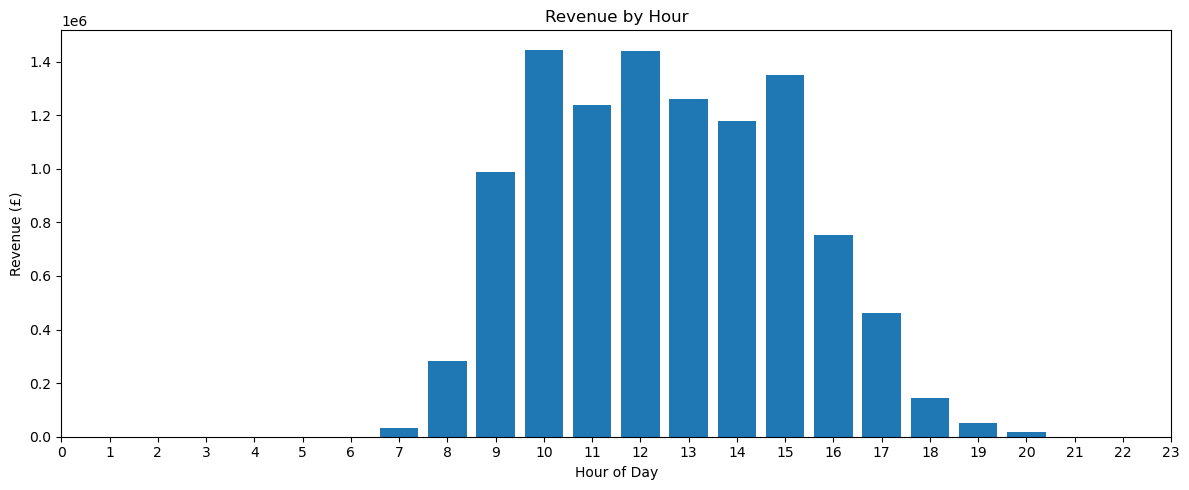

In [115]:
plt.figure(figsize=(12, 5))

plt.bar(
    hourly_sales.index,
    hourly_sales.values
)

plt.title('Revenue by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Revenue (£)')
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()

In [116]:
customer_summary['Total_Orders'].describe()

count    4338.000000
mean        4.272015
std         7.697998
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max       209.000000
Name: Total_Orders, dtype: float64

### Customer Order Frequency Analysis

The analysis shows that customer order frequency is highly skewed.

There are 4,338 identified customers, with an average of approximately 4.27 orders per customer. However, the median customer placed only 2 orders, while 75% of customers placed 5 or fewer orders.

The maximum number of orders by a single customer was 209.

The difference between the mean and median indicates that a relatively small group of highly active customers contributes significantly to the overall order frequency.

In [117]:
one_time_customers = (
    customer_summary['Total_Orders'] == 1
).sum()

repeat_customers = (
    customer_summary['Total_Orders'] > 1
).sum()

total_customers = len(customer_summary)

one_time_percentage = (
    one_time_customers / total_customers
) * 100

repeat_percentage =(
    repeat_customers / total_customers
) * 100

print("One-time Customers:", one_time_customers)
print("Repeat Customers:", repeat_customers)
print("One-time Customer Percentage:", one_time_percentage)

One-time Customers: 1493
Repeat Customers: 2845
One-time Customer Percentage: 34.41678192715537


### Customer Retention Analysis

Among the 4,338 identified customers, 1,493 customers (34.4%) made only one purchase, while 2,845 customers (65.6%) made multiple purchases.

This indicates that the majority of identified customers were repeat customers, suggesting relatively strong customer retention.

However, approximately one-third of customers purchased only once, representing a potential opportunity to improve customer retention and encourage repeat purchases.

In [118]:
customer_summary['Customer_Type'] = np.where(
    customer_summary['Total_Orders'] == 1,
    'One-time',
    'Repeat'
)

customer_type_revenue = (
    customer_summary
    .groupby('Customer_Type')['Total_Revenue']
    .sum()
    .reset_index()
)

customer_type_revenue

,Customer_Type,Total_Revenue
0,One-time,613989.561
1,Repeat,8273219.333


### Customer Revenue by Purchase Type

Repeat customers generated £8.27 million in revenue, accounting for approximately 93.1% of revenue generated by identified customers.

In comparison, one-time customers generated approximately £613.99K, contributing only 6.9% of identified-customer revenue.

This indicates that repeat customers are a major driver of the business and highlights the importance of customer retention and repeat purchasing.

In [119]:
customer_type_summary =(
    customer_summary
    .groupby('Customer_Type')
    .agg(
        customers=('CustomerID', 'count'),
        Total_Revenue=('Total_Revenue', 'sum')
    )
    .reset_index()
)

customer_type_summary['Revenue_Per_customer'] = (
    customer_type_summary['Total_Revenue'] / 
    customer_type_summary['customers']
)

customer_type_summary

,Customer_Type,customers,Total_Revenue,Revenue_Per_customer
0,One-time,1493,613989.561,411.245520
1,Repeat,2845,8273219.333,2907.985706


### Revenue per Customer by Purchase Type

One-time customers generated an average of approximately £411.25 per customer, while repeat customers generated approximately £2,907.99 per customer.

This means that repeat customers generated approximately 7.1 times more revenue per customer than one-time customers.

The finding highlights the strong financial value of customer retention and repeat purchasing. Encouraging one-time customers to make additional purchases could significantly increase customer lifetime value and overall revenue.

In [120]:
print("Final Dataset Shape:", df.shape)
print("Missing CustomerID:", df['CustomerID'].isnull().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("Negative Quantity:", (df['Quantity'] < 0).sum())
print("Zero UnitPrice:", (df['UnitPrice'] == 0).sum())
print("Negative UnitPrice:", (df['UnitPrice'] < 0).sum())
print("Zero Revenue:", (df['Revenue'] == 0).sum())
print("Negative Revenue:", (df['Revenue'] < 0).sum())


Final Dataset Shape: (524878, 15)
Missing CustomerID: 132186
Duplicate Rows: 0
Negative Quantity: 0
Zero UnitPrice: 0
Negative UnitPrice: 0
Zero Revenue: 0
Negative Revenue: 0


### Final Data Quality Check

The final dataset contains 524,878 rows and 15 columns.

The data quality checks confirmed that:
- There are no duplicate rows.
- There are no negative quantities.
- There are no zero or negative unit prices.
- There are no zero or negative revenue values.
- 132,186 records have missing CustomerID values.

The missing CustomerID values were retained because these transactions are still valid for overall sales, product, country, and time-based analysis. Customer-level analysis was performed separately using only records with available CustomerID values.

In [121]:
customer_summary['Customer_Type'] = np.where(
    customer_summary['Total_Orders'] == 1,
    'One-time',
    'Repeat'
)

customer_summary[['CustomerID', 'Total_Orders', 'Customer_Type']].head()


,CustomerID,Total_Orders,Customer_Type
0,12346.0,1,One-time
1,12347.0,7,Repeat
2,12348.0,4,Repeat
3,12349.0,1,One-time
4,12350.0,1,One-time


In [122]:
customer_summary.to_csv("customer_summary.csv", index=False)

In [123]:
customer_summary['Customer_Type'] = np.where(
    customer_summary['Total_Orders'] == 1,
    'One-time',
    'Repeat'
)

customer_summary[['CustomerID', 'Total_Orders', 'Customer_Type']].head()

,CustomerID,Total_Orders,Customer_Type
0,12346.0,1,One-time
1,12347.0,7,Repeat
2,12348.0,4,Repeat
3,12349.0,1,One-time
4,12350.0,1,One-time


In [124]:
customer_summary.to_csv("customer_summary.csv", index=False)

In [125]:
import os
os.path.exists("customer_summary.csv")

True